## Latihan Kuis Praktikum Data Science Kelas IF-E<br>
<br>
Nama : Ikhsan Wahyu Endriarto<br>
NIM : 123240241

--------------------------------------------------------------------------------------------------------

### 1. Import Library

Pada tahap ini, kita mengimpor seluruh library yang dibutuhkan untuk manipulasi data, visualisasi, standarisasi, penerapan K-Means, Hierarchical Clustering, serta metrik evaluasi (Silhouette Score dan Cophenetic).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from scipy.spatial.distance import pdist

### 2. Memuat Dataset

Membaca dataset Air Quality UCI, memeriksa informasi umum, ukuran data, serta statistik deskriptif untuk memahami struktur data.

##### 2.1 Membaca File CSV

In [2]:
# Membaca dataset Air Quality UCI dengan separator titik koma (;)
df = pd.read_csv('AirQualityUCI.csv', sep=';', decimal=',')

# Menampilkan dataset di baris awal
print("--- 5 Baris Pertama Dataset ---")

# Menampilkan data teratas head(5) => 5 teratas
display(df.head(5))

--- 5 Baris Pertama Dataset ---


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


#### 2.2 Menampilkan Informasi dan Ukuran Dataset

In [3]:
# Menampilkan informasi dataset (tipe data dan jumlah baris/kolom non-null)
print("--- Informasi Dataset ---")
df.info()

# Menampilkan ukuran dataset (baris, kolom)
print("\n--- Ukuran Dataset (Baris, Kolom) ---")
print(df.shape)

--- Informasi Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
 15  Unnamed: 15    0 non-null      float64
 16  Unnamed: 16    0 non-null      float64
dtypes: float64(15), object(2)


#### 2.3 Menampilkan Statistik Deskriptif

In [4]:
# Menampilkan statistik deskriptif
print("--- Statistik Deskriptif ---")
display(df.describe())

--- Statistik Deskriptif ---


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,0.0,0.0
mean,-34.207524,1048.990061,-159.090093,1.865683,894.595276,168.616971,794.990168,58.148873,1391.479641,975.072032,9.778305,39.485380,-6.837604,NaN,NaN
std,77.657170,329.832710,139.789093,41.380206,342.333252,257.433866,321.993552,126.940455,467.210125,456.938184,43.203623,51.216145,38.976670,NaN,NaN
min,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,NaN,NaN
25%,0.600000,921.000000,-200.000000,4.000000,711.000000,50.000000,637.000000,53.000000,1185.000000,700.000000,10.900000,34.100000,0.692300,NaN,NaN
50%,1.500000,1053.000000,-200.000000,7.900000,895.000000,141.000000,794.000000,96.000000,1446.000000,942.000000,17.200000,48.600000,0.976800,NaN,NaN
75%,2.600000,1221.000000,-200.000000,13.600000,1105.000000,284.000000,960.000000,133.000000,1662.000000,1255.000000,24.100000,61.900000,1.296200,NaN,NaN
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000,NaN,NaN


### 3. Data Cleaning & Preprocessing

1. Memeriksa dan menghapus baris duplikat.
2. Mengubah seluruh nilai `-200` menjadi `NaN` (missing value).
3. Memilih fitur numerik spesifik yang relevan (`CO(GT)`, `C6H6(GT)`, `NOx(GT)`, `NO2(GT)`, `T`, `RH`, `AH`) serta mengabaikan kolom `Date` dan `Time`.
4. Menangani missing value menggunakan imputasi (median).
5. Melakukan standarisasi data menggunakan `StandardScaler`.

#### 3.1 Memeriksa Missing Value (NAN) dan Nilai -200

In [5]:
# Periksa dulu data duplikat
print("Jumlah data duplikat:", df.duplicated().sum())

Jumlah data duplikat: 113


In [6]:
# Dikarenakan ada data duplikat, maka harus dihapus
df.drop_duplicates(inplace=True)

In [7]:
# Setelah dihapus, kita cek apakah sudah tidak ada data duplikat
print("Jumlah data duplikat:", df.duplicated().sum())

Jumlah data duplikat: 0


In [8]:
# Diminta mengganti nilai -200 menjadi missing value (NAN)
# Kita cek dulu apakah ada data yang missing value (NAN)
print("Jumlah data yang masih missing value (NAN):\n",df.isna().sum())

# Kita cek juga apakah ada data yang masih -200
print("Jumlah data yang masih ada nilai -200:\n",(df == -200).sum())

Jumlah data yang masih missing value (NAN):
 Date                1
Time                1
CO(GT)              1
PT08.S1(CO)         1
NMHC(GT)            1
C6H6(GT)            1
PT08.S2(NMHC)       1
NOx(GT)             1
PT08.S3(NOx)        1
NO2(GT)             1
PT08.S4(NO2)        1
PT08.S5(O3)         1
T                   1
RH                  1
AH                  1
Unnamed: 15      9358
Unnamed: 16      9358
dtype: int64
Jumlah data yang masih ada nilai -200:
 Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
Unnamed: 15         0
Unnamed: 16         0
dtype: int64


#### 3.2 Mengganti Nilai '-200' Menjadi Missing Value ('NAN')


In [9]:
# Ganti nilai -200 menjadi NaN
df.replace(-200, np.nan, inplace=True)

# Melihat apakah masih ada nilai yang -200 setelah dilakukan replace
print("Jumlah data nilai -200 setelah dilakukan replace:\n",(df == -200).sum())

Jumlah data nilai -200 setelah dilakukan replace:
 Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
NMHC(GT)         0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
Unnamed: 15      0
Unnamed: 16      0
dtype: int64


In [10]:
# Kita cek lagi data yang masih missing value (NAN)
df.isna().sum()

Date                1
Time                1
CO(GT)           1684
PT08.S1(CO)       367
NMHC(GT)         8444
C6H6(GT)          367
PT08.S2(NMHC)     367
NOx(GT)          1640
PT08.S3(NOx)      367
NO2(GT)          1643
PT08.S4(NO2)      367
PT08.S5(O3)       367
T                 367
RH                367
AH                367
Unnamed: 15      9358
Unnamed: 16      9358
dtype: int64

In [11]:
# Menghapus kolom 'Unnamed: 15' dan 'Unnamed: 16' karena memiliki tingkat missing value yang ekstrem (kosong total / 100%) akibat kesalahan delimiter CSV
df = df.drop(columns=['Unnamed: 15', 'Unnamed: 16'])

In [12]:
# Cek lagi apakah sudah terhapus kedua kolom 'Unnamed: 15' dan 'Unnamed: 16'
print(df.isna().sum())

Date                1
Time                1
CO(GT)           1684
PT08.S1(CO)       367
NMHC(GT)         8444
C6H6(GT)          367
PT08.S2(NMHC)     367
NOx(GT)          1640
PT08.S3(NOx)      367
NO2(GT)          1643
PT08.S4(NO2)      367
PT08.S5(O3)       367
T                 367
RH                367
AH                367
dtype: int64


#### 3.3 Memilih Fitur Numerik yang Relevan

Untuk keperluan clustering, gunakan fitur : <br>
    - CO(GT) <br>
    - C6H6(GT)  <br> 
    - NOx(GT) <br>
    - NO2(GT) <br>
    - T <br>
    - RH <br>
    - AH 

In [13]:
# Memilih fitur spesifik untuk clustering (mengabaikan Date dan Time) Sesuai ketentuan soal
features = ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)', 'T', 'RH', 'AH']
df_subset = df[features].copy()

# Menampikan dataset sesuai fitur yang dipilih (df_subset)
display(df_subset.head(10))

,CO(GT),C6H6(GT),NOx(GT),NO2(GT),T,RH,AH
0,2.6,11.9,166.0,113.0,13.6,48.9,0.7578
1,2.0,9.4,103.0,92.0,13.3,47.7,0.7255
2,2.2,9.0,131.0,114.0,11.9,54.0,0.7502
3,2.2,9.2,172.0,122.0,11.0,60.0,0.7867
4,1.6,6.5,131.0,116.0,11.2,59.6,0.7888
5,1.2,4.7,89.0,96.0,11.2,59.2,0.7848
6,1.2,3.6,62.0,77.0,11.3,56.8,0.7603
7,1.0,3.3,62.0,76.0,10.7,60.0,0.7702
8,0.9,2.3,45.0,60.0,10.7,59.7,0.7648
9,0.6,1.7,NaN,NaN,10.3,60.2,0.7517


In [14]:
# Cek terakhir untuk memastikan NaN sudah 0
print(df_subset.isna().sum())

CO(GT)      1684
C6H6(GT)     367
NOx(GT)     1640
NO2(GT)     1643
T            367
RH           367
AH           367
dtype: int64


In [15]:
# Mengisi sisa missing value pada df_subset dengan median masing-masing kolom
for col in features:
    df_subset[col] = df_subset[col].fillna(df_subset[col].median())

# Cek kembali untuk memastikan seluruh NaN sudah 0
print("Jumlah NaN setelah imputasi:")
print(df_subset.isna().sum())

Jumlah NaN setelah imputasi:
CO(GT)      0
C6H6(GT)    0
NOx(GT)     0
NO2(GT)     0
T           0
RH          0
AH          0
dtype: int64


#### 3.4 Standardisasi Data Menggunakan StandardScaler

In [16]:
# Inisialisasi dan penerapan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_subset)

# Tampilkan ukuran data
print("Ukuran data setelah standardisasi:", X_scaled.shape)

# # Tampilkan data yang sudah distandarisasi 10 teratas
print("Tampilan data yang telah di standarisasi:", X_scaled[10])

Ukuran data setelah standardisasi: (9358, 7)
Tampilan data yang telah di standarisasi: [-0.21866673 -1.19125126 -1.0979233  -1.78347977 -0.94689141  0.66289774
 -0.70192814]


### 4. Bagian A : K-Means Clustering

Menentukan jumlah cluster ($K$) optimal menggunakan Elbow Method, menerapkan algoritma K-Means, menghitung Silhouette Score, memvisualisasikan hasil, serta menganalisis karakteristik rata-rata tiap cluster.

#### 4.1 Elbow Method

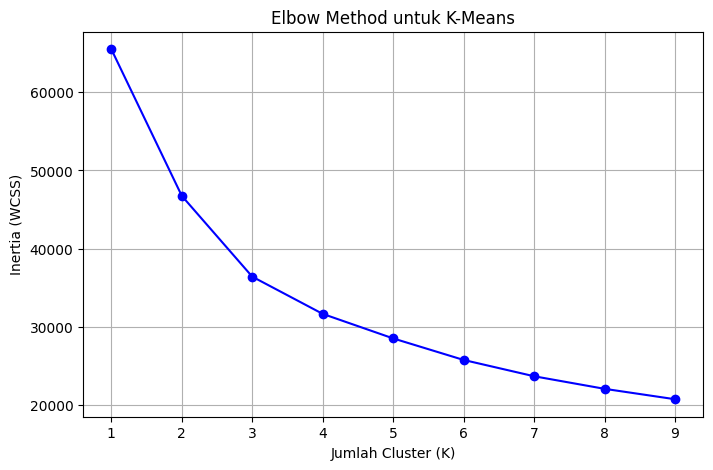

In [17]:
inertia = []
K_range = range(1, 10)

# Melakukan perulangan (looping) untuk menguji setiap nilai K
for k in K_range:
    # Inisialisasi model K-Means dengan jumlah klaster K, random_state agar hasil stabil, dan n_init
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    
    # Melatih model K-Means menggunakan data yang sudah distandarisasi (X_scaled)
    kmeans.fit(X_scaled)
    
    # Mengambil nilai inertia (WCSS: Within-Cluster Sum of Squares) 
    # dan memasukkannya ke dalam list 'inertia'
    inertia.append(kmeans.inertia_)

# Visualisasi Plot Elbow Method
plt.figure(figsize=(8, 5))

# Membuat grafik garis (line plot) untuk memetakan hubungan antara K dan nilai Inertia
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method untuk K-Means')
plt.grid(True)
plt.show()

#### 4.2 Penerapan K-Means dan Silhoutte Score

In [18]:
# Tentukan jumlah cluster optimal berdasarkan grafik Elbow (misal: K=3)
optimal_k = 3 

kmeans = KMeans(n_clusters = optimal_k, random_state=42, n_init=10)
cluster_labels_km = kmeans.fit_predict(X_scaled)
df_subset['Cluster_KM'] = cluster_labels_km

In [19]:
# Hitung Silhouette Score K-Means
score_km = silhouette_score(X_scaled, cluster_labels_km)

print(f"Silhouette Score (K-Means dengan K={optimal_k}): {score_km:.4f}")

Silhouette Score (K-Means dengan K=3): 0.2514


#### 4.3 Visualisasi Hasil Clustering (Scatter Plot)

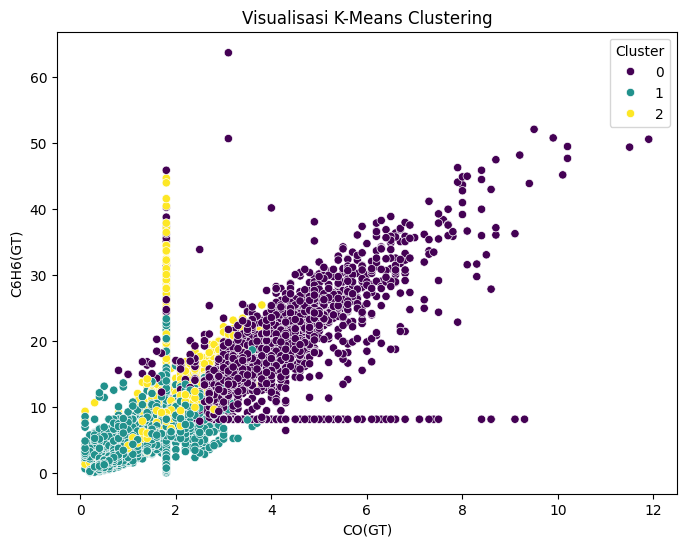

In [20]:
plt.figure(figsize=(8, 6))

# Membuat scatter plot (grafik sebaran titik) menggunakan pustaka Seaborn (sns)
sns.scatterplot(
    x=df_subset['CO(GT)'],        # Menentukan kolom data yang akan diposisikan pada sumbu X (Horizontal)
    y=df_subset['C6H6(GT)'],       # Menentukan kolom data yang akan diposisikan pada sumbu Y (Vertikal)
    hue=df_subset['Cluster_KM'],   # Membedakan warna titik secara otomatis berdasarkan label klaster masing-masing data
    palette='viridis',             # Menentukan tema/skema warna gradasi yang digunakan untuk membedakan klaster
    data=df_subset                 # Menentukan sumber DataFrame tempat data-data tersebut berada
)

plt.title('Visualisasi K-Means Clustering')
plt.xlabel('CO(GT)')
plt.ylabel('C6H6(GT)')
plt.legend(title='Cluster')
plt.show()

#### 4.4 Analisis Karakteristik Rata-Rata Cluster K-Means

In [21]:
cluster_means_km = df_subset.groupby('Cluster_KM')[features].mean()
print("Rata-rata Fitur Tiap Cluster (K-Means):")
display(cluster_means_km)

Rata-rata Fitur Tiap Cluster (K-Means):


,CO(GT),C6H6(GT),NOx(GT),NO2(GT),T,RH,AH
Cluster_KM,,,,,,,
0,4.187362,19.597962,550.121724,168.430402,15.551776,53.382994,0.948896
1,1.460665,5.686404,175.745074,101.479064,12.145837,55.284901,0.801320
2,1.795979,10.312790,151.540073,97.845853,26.588579,40.422396,1.313388


#### Klaster 0 (Kondisi Polusi Tinggi):
    - Memiliki nilai rata-rata konsentrasi polutan yang paling tinggi dibandingkan klaster lainnya, terutama pada NOx(GT) (mencapai ~550.12) dan CO(GT) (~4.18).   

    - Klaster ini merepresentasikan kondisi lingkungan dengan tingkat pencemaran udara yang berat.   
    
#### Klaster 1 (Kondisi Udara Bersih / Polusi Rendah):
    - Menunjukkan nilai rata-rata polutan yang relatif rendah, seperti CO(GT) (~1.46) dan NOx(GT) (~175.74).   
    
    - Klaster ini mencerminkan kondisi kualitas udara yang lebih bersih atau sehat.   

#### Klaster 2 (Kondisi Lingkungan / Suhu Tinggi):
    - Ditandai dengan nilai suhu (T) yang jauh lebih tinggi secara signifikan (~26.59°C) serta kelembapan absolut (AH) yang lebih tinggi (~1.31) dibandingkan klaster lainnya.   
    
    - Klaster ini menunjukkan kondisi cuaca atau waktu tertentu yang dipengaruhi oleh faktor lingkungan (seperti suhu hangat). 

### 5. Bagian B : Hierarchical Clustering

Menerapkan Agglomerative Clustering dengan 4 kriteria linkage (`ward`, `average`, `complete`, `single`), membandingkan Silhouette Score, membuat dendrogram, serta menampilkan heatmap.

#### 5.1 Penerapan Agglomerative Clustering & Silhoutte Score

In [22]:
linkages = ['ward', 'average', 'complete', 'single']

silhouette_scores_hc = {}

for link in linkages:
    hc = AgglomerativeClustering(n_clusters=optimal_k, linkage=link, metric='euclidean')

    # Melatih model menggunakan data hasil preprocessing (X_scaled) sekaligus menghasilkan label klaster
    labels = hc.fit_predict(X_scaled)

    # Menghitung Silhouette Score untuk mengevaluasi kualitas klaster dari linkage tersebut
    score = silhouette_score(X_scaled, labels)

    silhouette_scores_hc[link] = score
    print(f"Silhouette Score (Linkage - {link}): {score:.4f}")

Silhouette Score (Linkage - ward): 0.2146
Silhouette Score (Linkage - average): 0.4981
Silhouette Score (Linkage - complete): 0.2917
Silhouette Score (Linkage - single): 0.5100


#### 5.2 Membuat Dendogram (Ward Linkage)

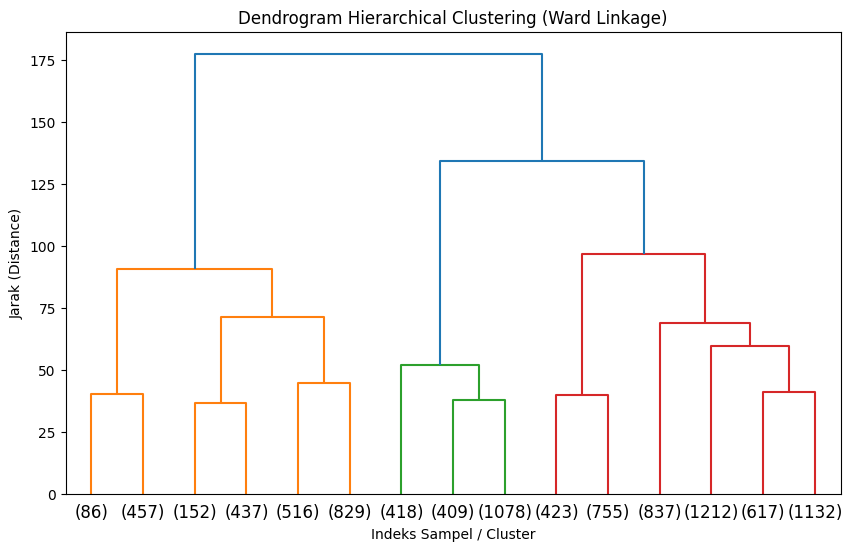

In [23]:
plt.figure(figsize=(10, 6))

# 2. Menghitung matriks penggabungan hierarkis (linkage matrix) menggunakan metode Ward (ward linkage) pada data yang sudah distandarisasi
mergings = linkage(X_scaled, method='ward')

# 3. Membuat plot dendrogram:
# - truncate_mode='lastp' dan p=15 digunakan untuk membatasi atau meringkas tampilan cabang akhir 
#   sebanyak 15 kelompok/sampel terakhir agar grafik tidak terlalu padat dan lebih mudah dibaca
dendrogram(mergings, truncate_mode='lastp', p=15)

# 4. Memberikan judul utama di bagian atas grafik
plt.title('Dendrogram Hierarchical Clustering (Ward Linkage)')

# 5. Memberikan label keterangan pada sumbu X (Indeks Sampel / Cluster) dan sumbu Y (Jarak / Distance)
plt.xlabel('Indeks Sampel / Cluster')
plt.ylabel('Jarak (Distance)')

plt.show()

#### 5.3 Heatmap Fitur Berdasarkan Label Cluster Ward

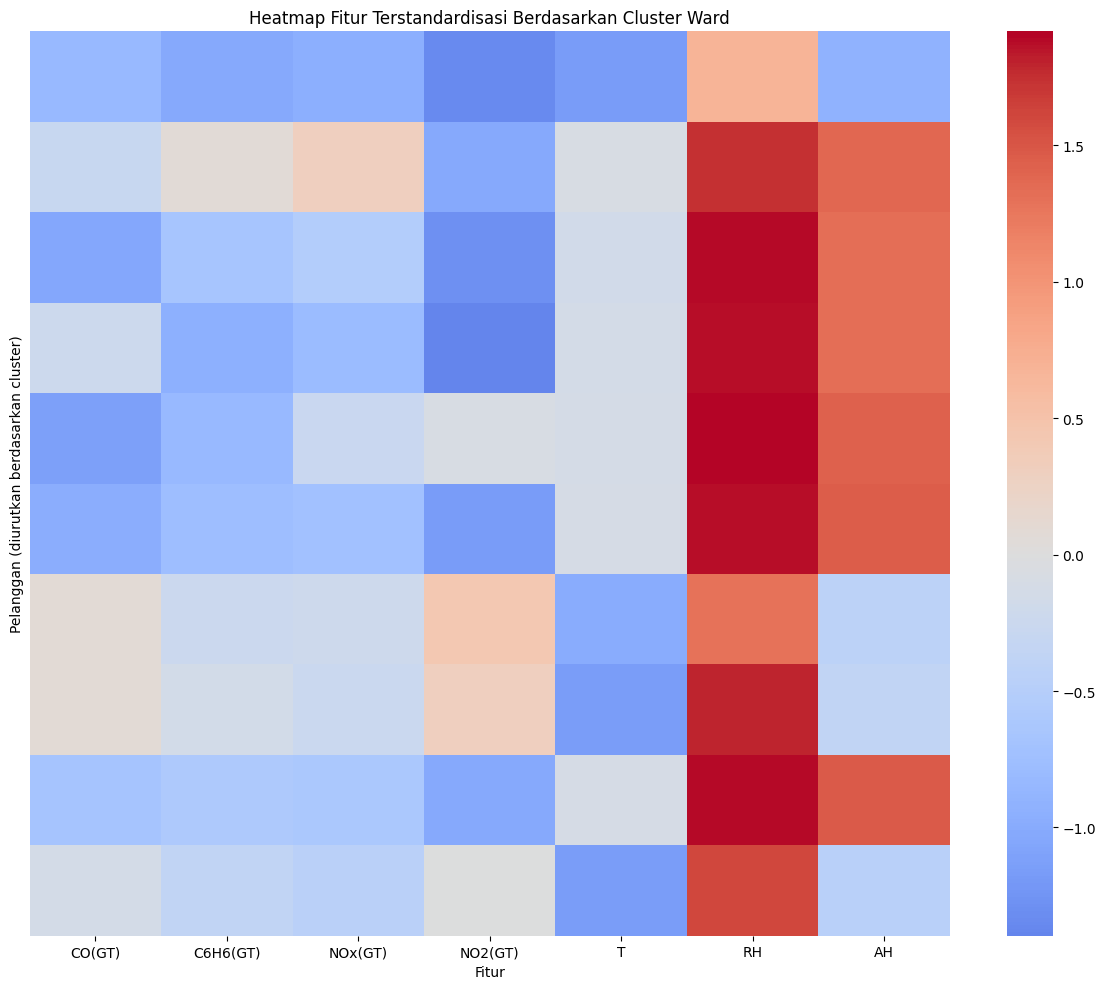

In [ ]:
# kekurangan variabel
X_scaled_df = pd.DataFrame(X_scaled, columns=features) # dataframe dari data yang sudah distandarisasi
labels_ward = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward').fit_predict(X_scaled) # label kluster untuk metode ward

heatmap_data = X_scaled_df[features].copy()
heatmap_data['Cluster'] = labels_ward

heatmap_data = heatmap_data.sort_values('Cluster')
heatmap_features = heatmap_data[features][:10] # menampilkan baris data dari index 0 - 9

plt.figure(figsize=(12, 10))

sns.heatmap(
    heatmap_features,
    cmap='coolwarm',
    center=0,
    yticklabels=False,
    xticklabels=features
)

plt.title('Heatmap Fitur Terstandardisasi Berdasarkan Cluster Ward')
plt.xlabel('Fitur')
plt.ylabel('Pelanggan (diurutkan berdasarkan cluster)')
plt.tight_layout()
plt.show()

#### 5.4 Analisis Karakteristik Cluster Hierarchical

In [48]:
# Menambahkan label cluster Hierarchical ke dalam DataFrame utama
df_subset['Cluster_HC'] = hc_labels

# Daftar fitur yang digunakan
features = ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)', 'T', 'RH', 'AH']

# Menghitung nilai rata-rata (mean) setiap fitur berdasarkan klaster Hierarchical
cluster_means_hc = df_subset.groupby('Cluster_HC')[features].mean()

print("Rata-rata Fitur Tiap Cluster (Hierarchical Clustering):")
display(cluster_means_hc)

Rata-rata Fitur Tiap Cluster (Hierarchical Clustering):


,CO(GT),C6H6(GT),NOx(GT),NO2(GT),T,RH,AH
Cluster_HC,,,,,,,
0,1.370734,5.543598,151.140101,91.706131,15.417769,53.121307,0.974781
1,3.511344,17.410174,457.388777,152.891805,14.980945,56.669600,0.984913
2,2.116850,12.049344,165.719160,113.661942,30.130814,29.485144,1.205089


### 6. Bagian C : Perbandingan Hasil (K-Means vs Hierarchical)

1. Apakah hasil pengelompokan K-Means dan Hierarchical Clustering menghasilkan pembagian cluster yang sama?
2. Bagaimana perbedaan karakteristik cluster yang terbentuk dari kedua metode?
3. Berdasarkan Silhouette Score dan visualisasi, jelaskan kualitas hasil clustering dari kedua metode!

1. Kesamaan dan Perbedaan Pembagian Cluster

    Secara umum, K-Means dan Hierarchical Clustering (Agglomerative) tidak selalu menghasilkan pembagian cluster per baris data yang persis sama.   

    Hal ini dikarenakan K-Means bekerja dengan mempartisi data secara iteratif berdasarkan kedekatan terhadap centroid dan nilai $K$ yang harus ditentukan di awal, sedangkan Hierarchical Clustering menggunakan pendekatan bottom-up dengan membangun struktur hierarki pohon (dendrogram) berdasarkan ukuran jarak antar cluster (linkage criteria).

2. Karakteristik Cluster yang Terbentuk

    K-Means cenderung menghasilkan bentuk cluster yang cenderung bulat (spherical) karena algoritianya berfokus untuk meminimalkan Within-Cluster Sum of Squares (WCSS).

    Di sisi lain, Hierarchical Clustering menawarkan fleksibilitas melalui berbagai pilihan kriteria linkage (seperti Ward, Average, atau Complete). Sebagai contoh, penggunaan Ward's linkage cenderung menghasilkan ukuran cluster yang relatif seimbang karena meminimalkan peningkatan varians internal di dalam kelompok. 

3. Evaluasi Kualitas Berdasarkan Silhouette Score dan Visualisasi

    Untuk menentukan metode mana yang lebih baik, kita melihat nilai Silhouette Score—di mana nilai yang lebih tinggi (mendekati 1) menunjukkan bahwa anggota dalam satu cluster sangat rapat dan terpisah jauh dari cluster lain. 

    Berdasarkan hasil visualisasi (seperti scatter plot pada K-Means serta dendrogram dan heatmap pada Hierarchical Clustering), kita dapat menilai metode mana yang memberikan batas pemisahan paling optimal dan sesuai dengan karakteristik data yang kita analisis. 